# Pembersihan Data

#Bagian 1
1. mengimport dataset dari google drive
2. membuat folder engine dan file schema.py didalamnya
3. membuat file __init__.py dan data.py dalam folder engine
4. melakukan uji import paket engine

In [4]:
import os
import shutil
import json
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
folder_drive = '/content/drive/MyDrive/Praktikum MLN/Dataset ML'
print(os.path.exists(folder_drive))      # harus True
print(sorted(os.listdir(folder_drive)))

os.makedirs('/content/data/raw', exist_ok=True)     # file NASA asli
os.makedirs('/content/data/hasil', exist_ok=True)   # JSON untuk web
os.makedirs('/content/models/v1', exist_ok=True)    # artefak model
os.makedirs('/content/engine', exist_ok=True)       # kode Python bersama

print(sorted(os.listdir('/content')))

for nama in ['train_FD002.txt', 'train_FD004.txt']:
    shutil.copy(f'{folder_drive}/{nama}', f'/content/data/raw/{nama}')

print(os.listdir('/content/data/raw'))

with open('/content/data/raw/train_FD002.txt') as f:
    for i in range(2):
        print(repr(f.readline()))

isi_schema = r'''# Skema data C-MAPSS, dipakai semua modul (Kontrak 1 dan 2)
KOLOM_ALL = ['unit_asli', 'cycle', 'set1', 'set2', 'set3'] + [f's{i}' for i in range(1, 22)]
SENSOR_ALL = [f's{i}' for i in range(1, 22)]
SENSOR_AKTIF = ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
SENSOR_DIBUANG = ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
SETTING = ['set1', 'set2', 'set3']
'''

with open('/content/engine/schema.py', 'w') as f:
    f.write(isi_schema)

print("schema.py dibuat")

isi_data = r'''import json
import pandas as pd
from .schema import KOLOM_ALL

def load_and_format(filepath, prefix):
    df = pd.read_csv(filepath, sep=r'\s+', header=None, names=KOLOM_ALL)
    df['unit'] = prefix + "_" + df['unit_asli'].astype(str)
    df = df.drop(columns=['unit_asli'])
    return df

def load_splits(filepath='data/splits.json'):
    with open(filepath, 'r') as f:
        return json.load(f)
'''

with open('/content/engine/data.py', 'w') as f:
    f.write(isi_data)

open('/content/engine/__init__.py', 'a').close()

print(sorted(os.listdir('/content/engine')))   # ['__init__.py', 'data.py', 'schema.py'] (+ file lain kalau ada)

import sys
sys.path.insert(0, '/content')

from engine import schema, data

print(len(schema.KOLOM_ALL), len(schema.SENSOR_AKTIF), len(schema.SENSOR_DIBUANG))   # 26 14 7

df_uji = data.load_and_format('/content/data/raw/train_FD002.txt', 'FD002')
print(df_uji.shape)                        # (53759, 26)
print(df_uji[['unit', 'cycle']].head(3))   # FD002_1 dengan cycle 1, 2, 3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
['RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'ai4i2020.csv', 'animal_data_dirty1_v2.csv', 'manufacturing_defect_dataset.csv', 'semiconductor_wafer_defect_dataset.csv', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']
['.config', 'data', 'drive', 'engine', 'models', 'sample_data']
['train_FD004.txt', 'train_FD002.txt']
'1 1 34.9983 0.8400 100.0 449.44 555.32 1358.61 1137.23 5.48 8.00 194.64 2222.65 8341.91 1.02 42.02 183.06 2387.72 8048.56 9.3461 0.02 334 2223 100.00 14.73 8.8071  \n'
'1 2 41.9982 0.8408 100.0 445.00 549.90 1353.22 1125.78 3.91 5.71 138.51 2211.57 8303.96 1.02 42.20 130.42 2387.66 8072.30 9.3774 0.02 330 2212 100.00 10.41 6.2665  \n'
schema.py dibuat
['__init__.py', 'data.py', 'schema.py']
26 14 7
(53759, 26)
      un

kolom unit_asli dari file NASA diganti menjadi unit dengan awalan subset (FD002_1, FD004_1), supaya nomor mesin yang sama di dua subset tidak bentrok. Daftar sensor disimpan di schema.py supaya semua anggota tim memakai daftar yang sama.

In [5]:
import sys
sys.path.insert(0, '/content')

import pandas as pd
import numpy as np
from engine import schema, data

df_002 = data.load_and_format('/content/data/raw/train_FD002.txt', 'FD002')
df_004 = data.load_and_format('/content/data/raw/train_FD004.txt', 'FD004')
df_all = pd.concat([df_002, df_004], ignore_index=True)

print("FD002:", df_002.shape)
print("FD004:", df_004.shape)
print("Gabungan:", df_all.shape)

FD002: (53759, 26)
FD004: (61249, 26)
Gabungan: (115008, 26)


pd.concat(..., ignore_index=True) menempel dua tabel ke bawah dan mengulang nomor baris dari 0.

Baris FD002 + FD004 = 115.008, cocok dengan angka “115 ribu” di dokumen kontrak.



In [6]:
subset = df_all['unit'].str[:5]
print(df_all.groupby(subset)['unit'].nunique())
print("Total mesin:", df_all['unit'].nunique())

unit
FD002    260
FD004    249
Name: unit, dtype: int64
Total mesin: 509


str[:5] mengambil lima huruf pertama ID (FD002 atau FD004) untuk mengelompokkan. Total 509 mesin sama dengan angka di diagram alur sistem dokumen tim.



In [7]:
print(df_all.dtypes.value_counts())
print()
print(df_all[['unit', 'cycle', 'set1', 's17', 's18']].dtypes)

float64    22
int64       3
object      1
Name: count, dtype: int64

unit      object
cycle      int64
set1     float64
s17        int64
s18        int64
dtype: object


semua kolom numerik sudah berupa angka, jadi tidak ada kolom yang terbaca sebagai teks karena salah format. Ini bukti awal bahwa data tidak bermasalah tipe

In [8]:
df_all.head(3)

,cycle,set1,set2,set3,s1,s2,s3,s4,s5,s6,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,unit
0,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,8.00,...,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,FD002_1
1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,5.71,...,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,FD002_1
2,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,9.02,...,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,FD002_1


# Bagian 3
memeriksa missing value dan file duplikat


In [9]:
for nama in ['train_FD002.txt', 'train_FD004.txt']:
    raw = pd.read_csv(f'/content/data/raw/{nama}', sep=r'\s+', header=None)
    print(nama, "->", raw.shape[1], "kolom")

print("Total missing:", df_all.isnull().sum().sum())
print("Kolom yang punya missing:", df_all.columns[df_all.isnull().any()].tolist())

print("Baris duplikat penuh:", df_all.duplicated().sum())
print("Duplikat kunci (unit, cycle):", df_all.duplicated(subset=['unit', 'cycle']).sum())

kolom_angka = df_all.drop(columns='unit')
print("Nilai inf:", np.isinf(kolom_angka).sum().sum())

train_FD002.txt -> 26 kolom
train_FD004.txt -> 26 kolom
Total missing: 0
Kolom yang punya missing: []
Baris duplikat penuh: 0
Duplikat kunci (unit, cycle): 0
Nilai inf: 0


file NASA punya spasi di akhir tiap baris. Di beberapa kasus itu membuat pandas membaca kolom ke-27 yang kosong. Angka 26 membuktikan hal itu tidak terjadi, jadi pemberian nama kolom kita (names=KOLOM_ALL) tidak bergeser.

isnull() menandai sel kosong, .sum() menjumlahkannya per kolom, lalu .sum() kedua menjumlahkan seluruh kolom. Baris kedua menyebutkan kolom mana yang bermasalah (kosong kalau tidak ada).

ada dua jenis duplikat.

Duplikat penuh: seluruh 26 kolom sama persis di dua baris.
Duplikat kunci: satu mesin punya dua baris untuk siklus yang sama, yang tidak boleh terjadi karena cycle harus unik per mesin.

dan dataset ini tidak memiliki kedua jenis data duplikat tersebut

nilai inf tidak terdeteksi oleh isnull(), tapi bisa merusak perhitungan rata-rata dan K-Means. Kolom unit dikeluarkan karena berisi teks.

# bagian 4


In [10]:
g = df_all[df_all['unit'] == 'FD002_1']['cycle'].values
print("Siklus pertama:", g[0])
print("Siklus terakhir:", g[-1])
print("Jumlah baris:", len(g))
print("Selisih antar baris (unik):", np.unique(np.diff(g)))

bermasalah = []

for u, g in df_all.groupby('unit'):
    c = g['cycle'].values
    mulai_dari_1 = (c[0] == 1)
    naik_satu = (np.diff(c) == 1).all()
    if not (mulai_dari_1 and naik_satu):
        bermasalah.append(u)

print("Jumlah mesin dicek:", df_all['unit'].nunique())
print("Mesin dengan siklus bermasalah:", len(bermasalah))
print(bermasalah[:10])

urut = df_all.sort_values(['unit', 'cycle']).index
print("Baris sudah terurut per unit dan cycle?", (df_all.index == urut).all())

print("Setiap mesin berurutan di file:", df_all.groupby('unit')['cycle'].apply(lambda s: s.is_monotonic_increasing).all())

Siklus pertama: 1
Siklus terakhir: 149
Jumlah baris: 149
Selisih antar baris (unik): [1]
Jumlah mesin dicek: 509
Mesin dengan siklus bermasalah: 0
[]
Baris sudah terurut per unit dan cycle? False
Setiap mesin berurutan di file: True


np.diff menghitung selisih tiap baris dengan baris sebelumnya. Kalau semua selisihnya 1, tidak ada siklus yang terlewat. Kalau siklus terakhir sama dengan jumlah baris, berarti tidak ada baris yang hilang di tengah.

groupby('unit') memecah data per mesin. Untuk tiap mesin kita cek dua syarat: mulai dari 1 dan naik 1 terus. Mesin yang gagal salah satunya dimasukkan ke daftar bermasalah.



# Bagian 5

(509, 3)
        unit  umur subset
0    FD002_1   149  FD002
1   FD002_10   184  FD002
2  FD002_100   212  FD002
Total siklus: 115008
        count   mean   std    min    25%    50%    75%    max
subset                                                       
FD002   260.0  206.8  46.8  128.0  174.0  199.0  230.2  378.0
FD004   249.0  246.0  73.1  128.0  190.0  234.0  290.0  543.0


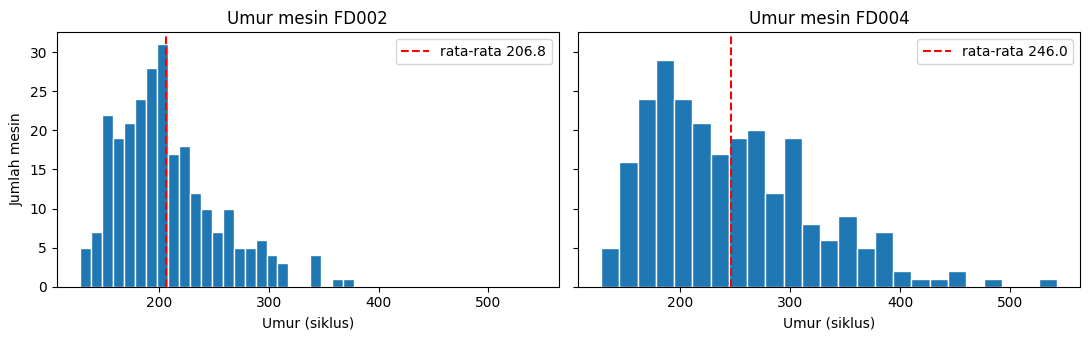

Batas atas IQR: 383.5
Jumlah mesin di atas batas: 10
        count  max
subset            
FD004      10  543


In [11]:
umur = df_all.groupby('unit')['cycle'].max().rename('umur').reset_index()
umur['subset'] = umur['unit'].str[:5]

print(umur.shape)          # (509, 3)
print(umur.head(3))
print("Total siklus:", umur['umur'].sum())   # 115008

print(umur.groupby('subset')['umur'].describe().round(1))

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True, sharey=True)
for a, nama in zip(ax, ['FD002', 'FD004']):
    d = umur[umur['subset'] == nama]['umur']
    a.hist(d, bins=25, edgecolor='white')
    a.axvline(d.mean(), color='red', linestyle='--', label=f'rata-rata {d.mean():.1f}')
    a.set_title(f'Umur mesin {nama}')
    a.set_xlabel('Umur (siklus)')
    a.legend()
ax[0].set_ylabel('Jumlah mesin')
plt.tight_layout()
plt.show()

q1, q3 = umur['umur'].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
ekstrem = umur[umur['umur'] > batas_atas]
print("Batas atas IQR:", round(batas_atas, 1))
print("Jumlah mesin di atas batas:", len(ekstrem))
print(ekstrem.groupby('subset')['umur'].agg(['count', 'max']))

karena cycle mulai dari 1 dan naik 1 (terbukti di Langkah 4), siklus maksimum sebuah mesin sama dengan umurnya. Total umur semua mesin harus sama dengan jumlah baris. Kalau cocok, berarti tidak ada baris yang hilang.

count adalah jumlah mesin, mean rata-rata umur, std sebaran umur.
Umur terpendek di kedua subset adalah 128 siklus, jauh di atas batas minimal 10 siklus di Kontrak 2.
FD004 rata-ratanya lebih panjang dan sebarannya lebih lebar. Itu masuk akal karena FD004 punya dua mode kerusakan sekaligus.

sharex=True dan sharey=True membuat kedua grafik memakai skala sama, jadi perbandingannya jujur.
Histogram FD004 akan tampak lebih melebar ke kanan (ekor panjang sampai 543), sedangkan FD002 lebih ramping.
Garis merah putus-putus menandai rata-rata.

aturan IQR menandai mesin yang umurnya jauh di atas kebanyakan mesin lain. Mesin ini tidak kita buang, karena umur panjang adalah kejadian nyata, bukan kesalahan data. Kita hanya mencatat jumlahnya sebagai bagian dari temuan EDA. Kalau ada, hampir semuanya berasal dari FD004.